In [47]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [48]:
words = open('names.txt').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [49]:
chars = sorted(list(set(''.join(words))))
stoi = {c : i+1 for i, c in enumerate(chars)} # create a mapping from character to index, starting from 1
stoi['.'] = 0
itos = {i : c for c, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [50]:
import random
random.seed(42)
random.shuffle(words)

In [51]:
# Train split, Val split, Test Split
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?
def build_dataset(words):
    X, Y = [], []
    for w in words:
        
        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])        # 80%
Xdev, Ydev = build_dataset(words[n1:n2])    # 10%
Xte, Yte = build_dataset(words[n2:])        # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [52]:
for x, y in zip(Xtr[:20], Ytr[:20]):
    print(''.join([itos[i.item()] for i in x]), "-->", itos[y.item()])

... --> y
..y --> u
.yu --> h
yuh --> e
uhe --> n
hen --> g
eng --> .
... --> d
..d --> i
.di --> o
dio --> n
ion --> d
ond --> r
ndr --> e
dre --> .
... --> x
..x --> a
.xa --> v
xav --> i
avi --> e


In [108]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x: torch.Tensor):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1D:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.dim = dim
        self.training = True

        # parameters (trained with backpropagation)
        self.gamma = torch.ones((1, dim)) # gain
        self.beta = torch.zeros((1, dim)) # bias

        # buffers (updated using momentum)
        self.running_mean = torch.zeros((1, dim))
        self.running_var = torch.ones((1, dim))

    def __call__(self, x: torch.Tensor):
        if self.training: 
            xmean = x.mean(dim=0, keepdim=True) # batch mean
            xvar = x.var(dim=0, keepdim=True, unbiased=True) # batch variance
        else:
            xmean = self.running_mean
            xvar = self.running_var

        x_hat = (x - xmean) / torch.sqrt(xvar + self.eps)

        self.out = self.gamma * x_hat + self.beta

        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar

        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []


class Embedding:
    def __init__(self, num_embeddings, embedding_dim):
        self.weight = torch.randn((num_embeddings, embedding_dim)) # this is the 'C'

    def __call__(self, IX):
        self.out = self.weight[IX]
        return self.out

    def parameters(self):
        return [self.weight]


class Flatten:
    def __call__(self, x):
        self.out = x.view(x.shape[0], -1)
        return self.out

    def parameters(self):
        return []

class Sequential:
    def __init__(self, layers):
        self.layers = layers
        with torch.no_grad():
            self.layers[-1].weight *= 0.1

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [109]:
torch.manual_seed(42);

In [110]:
n_embed = 10 # embedding vector dim
n_hidden = 200 # number of neurons in hidden layer

model = Sequential([
    Embedding(vocab_size, n_embed),
    Flatten(),
    Linear(n_embed * block_size, n_hidden, bias=False),
    BatchNorm1D(n_hidden),
    Tanh(),
    Linear(n_hidden, vocab_size)
])



parameters = model.parameters()
print("Number of parameters :", sum(p.nelement() for p in parameters))

for p in parameters:
    p.requires_grad = True


Number of parameters : 12097


In [111]:
# training

max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    # minibactch
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, yb = Xtr[ix], Ytr[ix]

    # Forward Pass
    logits = model(Xb)

    loss = F.cross_entropy(logits, yb) # loss function

    # backard pass
    for p in parameters:
        p.grad = None
        
    loss.backward()

    # update: simple SGD
    lr = 0.1 if i < 150000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    

      0/ 200000: 3.2966
  10000/ 200000: 2.2322
  20000/ 200000: 2.4111
  30000/ 200000: 2.1004
  40000/ 200000: 2.3157
  50000/ 200000: 2.2104
  60000/ 200000: 1.9653
  70000/ 200000: 1.9767
  80000/ 200000: 2.6738
  90000/ 200000: 2.0837
 100000/ 200000: 2.2730
 110000/ 200000: 1.7491
 120000/ 200000: 2.2891
 130000/ 200000: 2.3443
 140000/ 200000: 2.1731
 150000/ 200000: 1.8246
 160000/ 200000: 1.7614
 170000/ 200000: 2.2419
 180000/ 200000: 2.0803
 190000/ 200000: 2.1326


In [ ]:
# put layers into eval mode
for layer in model.layers:
    layer.training = False

In [113]:
splits = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
}

@torch.no_grad() # disable gradient tracking
def split_loss(split):
    x, y = splits[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0583252906799316
val 2.1065292358398438


In [114]:
with torch.no_grad():
    for _ in range(20):
        out = []
        context = [0] * block_size # initialize with all ...
        while True:
            # forward pass
            logits = model(torch.tensor([context]))
            probs = F.softmax(logits, dim=1)
            # sample from the distribution
            ix = torch.multinomial(probs, num_samples=1).item()
            context = context[1:] + [ix]
            out.append(ix)
            if ix == 0:
                break
                
        print(''.join(itos[i] for i in out))

damiara.
alyzah.
fard.
azalee.
sayah.
ayvi.
reino.
sophemuellani.
ciaub.
alith.
sira.
liza.
jah.
grancealynna.
jamaur.
ben.
quan.
torie.
coria.
cer.


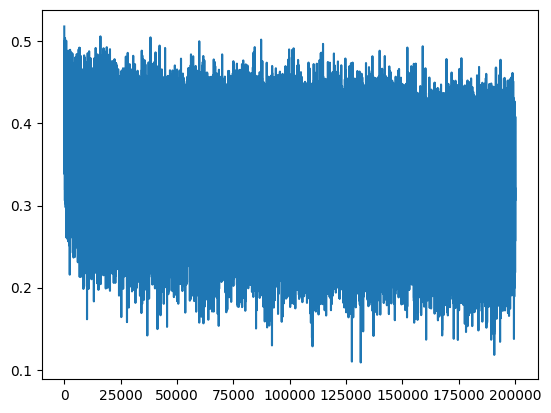

In [115]:
plt.plot(lossi);

Plot looks too ugly and it is not giving any useful insight. We can fix this. 

Lets divide the elements of lossi into froups of 1000 elements per group.

In [116]:
lossi[:10]

[0.5180676579475403,
 0.5164594054222107,
 0.507362961769104,
 0.507546603679657,
 0.4992470443248749,
 0.5014019012451172,
 0.5049523115158081,
 0.48866209387779236,
 0.4999050199985504,
 0.4899313449859619]

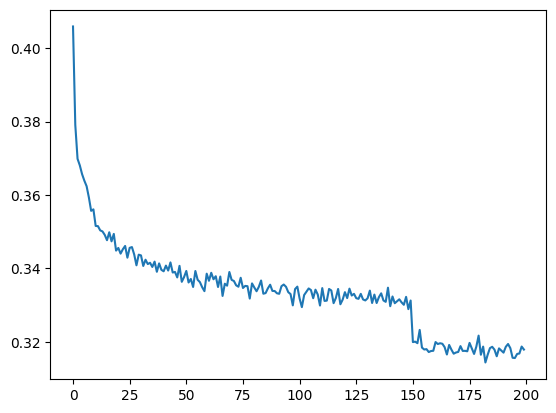

In [117]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(dim=1))

In [118]:
# C = torch.randn((vocab_size, n_embed))<--+
# emb = C[Xb]      <----- This is embedding operation 
# x = emb.view(emb.shape[0], -1) <----- This is flatten operation

# Lets add embedding and flattenig layers to the module and also sequential layer

##### Wavenet

In [121]:
# Train split, Val split, Test Split
# build the dataset
block_size = 8 # context length: how many characters do we take to predict the next one?
def build_dataset(words):
    X, Y = [], []
    for w in words:
        
        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])        # 80%
Xdev, Ydev = build_dataset(words[n1:n2])    # 10%
Xte, Yte = build_dataset(words[n2:])        # 10%

torch.Size([182625, 8]) torch.Size([182625])
torch.Size([22655, 8]) torch.Size([22655])
torch.Size([22866, 8]) torch.Size([22866])


In [215]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x: torch.Tensor):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1D:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.dim = dim
        self.training = True

        # parameters (trained with backpropagation)
        self.gamma = torch.ones((1, dim)) # gain
        self.beta = torch.zeros((1, dim)) # bias

        # buffers (updated using momentum)
        self.running_mean = torch.zeros((1, dim))
        self.running_var = torch.ones((1, dim))

    def __call__(self, x: torch.Tensor):
        if self.training: 
            if x.ndim == 2:
                dim = 0
            elif x.ndim == 3:
                dim = (0, 1)
            xmean = x.mean(dim=dim, keepdim=True) # batch mean
            xvar = x.var(dim=dim, keepdim=True, unbiased=True) # batch variance
        else:
            xmean = self.running_mean
            xvar = self.running_var

        x_hat = (x - xmean) / torch.sqrt(xvar + self.eps)

        self.out = self.gamma * x_hat + self.beta

        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar

        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []


class Embedding:
    def __init__(self, num_embeddings, embedding_dim):
        self.weight = torch.randn((num_embeddings, embedding_dim)) # this is the 'C'

    def __call__(self, IX):
        self.out = self.weight[IX]
        return self.out

    def parameters(self):
        return [self.weight]


class FlattenConsecutive:
    def __init__(self, n):
        # n = number of elements that are consecutive and we want to concatenate in last dim
        self.n = n
    def __call__(self, x):
        B, T, C = x.shape
        x = x.view(B, T // self.n, C * self.n) # expected #(B, T//n, C*n)
        if x.shape[1] == 1: # when all the pairing of all levels done, this dim will become 1 |  exmplained later
            x = x.squeeze(dim=1)
        self.out = x
        return self.out

    def parameters(self):
        return []

class Sequential:
    def __init__(self, layers):
        self.layers = layers
        with torch.no_grad():
            self.layers[-1].weight *= 0.1

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [216]:
n_embed = 24 # embedding vector dim
n_hidden = 128 # number of neurons in hidden layer

model = Sequential([
    Embedding(vocab_size, n_embed),
    FlattenConsecutive(2), # group of 2-2 
    Linear(n_embed  * 2, n_hidden, bias=False), BatchNorm1D(n_hidden), Tanh(),

    FlattenConsecutive(2), # group of 4-4
    Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1D(n_hidden), Tanh(),

    FlattenConsecutive(2), # group of 8-8 
    Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1D(n_hidden), Tanh(),

    Linear(n_hidden, vocab_size)
])



parameters = model.parameters()
print("Number of parameters :", sum(p.nelement() for p in parameters))

for p in parameters:
    p.requires_grad = True


Number of parameters : 76579


In [200]:
ix = torch.randint(0, Xtr.shape[0], (6, )) # lets take batch of 4 examples
Xb, yb = Xtr[ix], Ytr[ix]
logits = model(Xb)
print(Xb.shape)
Xb

torch.Size([6, 8])


tensor([[ 0,  0,  0,  0,  4,  5, 15, 14],
        [ 0,  0,  3,  1, 13, 15, 14,  9],
        [ 0,  0, 15, 12, 21, 23,  1, 13],
        [ 0,  0,  0,  0, 10,  5, 19,  9],
        [ 0,  0,  0,  6, 15, 12,  1, 10],
        [ 0,  0,  0,  0,  0,  0,  6,  1]])

In [201]:
logits.shape

torch.Size([6, 27])

In [202]:
model.layers[0].out.shape # output of embedding layer

torch.Size([6, 8, 10])

In [203]:
model.layers[1].out.shape # output of flatten layer

torch.Size([6, 4, 20])

In [204]:
model.layers[2].out.shape # output of linear layer

torch.Size([6, 4, 68])

In [205]:
print((torch.randn((6, 80)) @ torch.randn((80, 200)) + torch.randn(200)).shape) # similar to linear layer

print((torch.randn((6, 4, 80)) @ torch.randn((80, 200)) + torch.randn(200)).shape)

print((torch.randn((6, 8, 4, 80)) @ torch.randn((80, 200)) + torch.randn(200)).shape)

torch.Size([6, 200])
torch.Size([6, 4, 200])
torch.Size([6, 8, 4, 200])


In [206]:
#  1  2  3  4  5  6  7  8   Shape: (B, 8, 10)

# (1 2) (3 4) (5 6) (7 8)    <-- we want to process all the 4 dimentions in parallel like a batch | Shape: (B, 4, 20)
    
# # (1 2 3 4) (5 6 7 8)    Shape: (B, 2, 40)

# #  (1 2 3 4 5 6 7 8)    Shape: (B, 1, 80)  <--- euivalent to current emb: (torch.randn((6, 80))


In [207]:
print((torch.randn((6, 4, 20)) @ torch.randn((20, 200)) + torch.randn(200)).shape)

torch.Size([6, 4, 200])


In [208]:
# we need to change our flatten layer, we want (6, 4, 20) for following
e = torch.randn(6, 8, 10)

In [209]:
list(range(10))[::2] # evens

[0, 2, 4, 6, 8]

In [210]:
list(range(10))[1::2] # odds

[1, 3, 5, 7, 9]

In [211]:
explicit = torch.cat([e[:, ::2, :], e[:, 1::2, :]], dim=2)
explicit.shape

torch.Size([6, 4, 20])

In [212]:
(e.view(6, 4, 20) == explicit).all()

tensor(True)

In [217]:
# training

max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    # minibactch
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, yb = Xtr[ix], Ytr[ix]

    # Forward Pass
    logits = model(Xb)

    loss = F.cross_entropy(logits, yb) # loss function

    # backard pass
    for p in parameters:
        p.grad = None
        
    loss.backward()

    # update: simple SGD
    lr = 0.1 if i < 150000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    

      0/ 200000: 3.2972
  10000/ 200000: 2.2264
  20000/ 200000: 2.0343
  30000/ 200000: 2.1487
  40000/ 200000: 1.7005
  50000/ 200000: 1.6931
  60000/ 200000: 2.3234
  70000/ 200000: 2.0861
  80000/ 200000: 2.2632
  90000/ 200000: 2.3096
 100000/ 200000: 2.0032
 110000/ 200000: 1.7564
 120000/ 200000: 2.3565
 130000/ 200000: 1.8074
 140000/ 200000: 1.9283
 150000/ 200000: 2.2280
 160000/ 200000: 1.7153
 170000/ 200000: 1.5219
 180000/ 200000: 1.6905
 190000/ 200000: 1.5536


In [218]:
# put layers into eval mode
for layer in model.layers:
    layer.training = False

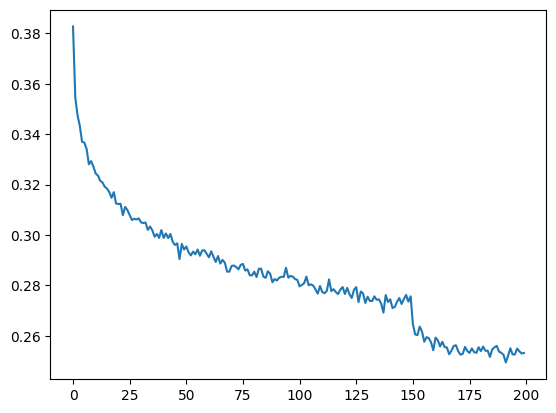

In [219]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(dim=1))

In [220]:
splits = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
}

@torch.no_grad() # disable gradient tracking
def split_loss(split):
    x, y = splits[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 1.7708103656768799
val 1.9918911457061768


In [214]:
model.layers[3].running_mean.shape

torch.Size([1, 1, 68])

In [ ]:
# Problem
# batch norm input is (32, 4, 68)

for layer in model.layers:
    print(layer.__class__.__name__, ":", tuple(layer.out.shape))

Embedding : (32, 8, 10)
FlattenConsecutive : (32, 4, 20)
Linear : (32, 4, 68)
BatchNorm1D : (32, 4, 68)
Tanh : (32, 4, 68)
FlattenConsecutive : (32, 2, 136)
Linear : (32, 2, 68)
BatchNorm1D : (32, 2, 68)
Tanh : (32, 2, 68)
FlattenConsecutive : (32, 136)
Linear : (32, 68)
BatchNorm1D : (32, 68)
Tanh : (32, 68)
Linear : (32, 27)


In [ ]:
e = torch.randn(32, 4, 68)
emean = e.mean(dim=0, keepdim=True) #(1, 4, 68) --> intended (1, 1, 68)
evar = e.var(dim=0, keepdim=True) #(1, 4, 68) --> intended (1, 1, 68)
ehat = (e - emean) / torch.sqrt(evar+1e-5) # (32, 4, 68) 
ehat.shape

torch.Size([32, 4, 68])

In [ ]:
e = torch.randn(32, 4, 68)
emean = e.mean(dim=(0, 1), keepdim=True) #(1, 1, 68)
evar = e.var(dim=(0, 1), keepdim=True) #(1, 1, 68)
ehat = (e - emean) / torch.sqrt(evar+1e-5) # (32, 4, 68)
print(emean.shape)
print(emean.shape)
ehat.shape

torch.Size([1, 1, 68])
torch.Size([1, 1, 68])


torch.Size([32, 4, 68])

In [221]:
with torch.no_grad():
    for _ in range(20):
        out = []
        context = [0] * block_size # initialize with all ...
        while True:
            # forward pass
            logits = model(torch.tensor([context]))
            probs = F.softmax(logits, dim=1)
            # sample from the distribution
            ix = torch.multinomial(probs, num_samples=1).item()
            context = context[1:] + [ix]
            out.append(ix)
            if ix == 0:
                break
                
        print(''.join(itos[i] for i in out))

lolynn.
geony.
lelane.
amelia.
varih.
mirray.
rylee.
chershaw.
vish.
timben.
paytenca.
meraclyne.
vaidis.
reeam.
ateilia.
phierra.
elalise.
gwyde.
renlee.
allis.


In [190]:
for layer in model.layers:
    print(layer.__class__.__name__, ":", tuple(layer.out.shape))

Embedding : (1, 8, 10)
FlattenConsecutive : (1, 4, 20)
Linear : (1, 4, 68)
BatchNorm1D : (1, 4, 68)
Tanh : (1, 4, 68)
FlattenConsecutive : (1, 2, 136)
Linear : (1, 2, 68)
BatchNorm1D : (1, 2, 68)
Tanh : (1, 2, 68)
FlattenConsecutive : (1, 136)
Linear : (1, 68)
BatchNorm1D : (1, 68)
Tanh : (1, 68)
Linear : (1, 27)


In [189]:
# Problem
# Batch norm is getting